# 04 · Volume Anomaly: the 2016 Slowdown

**Question:** annual volume stopped growing in 2016. When did it start, how large was the real decline, and how long did it last?

**Bottom line:** after a **one-off spike in March 2016 (\$949M)**, monthly funded volume fell **~12% below its 2015 run-rate (\$535M/month) for about a year**, recovering from May 2017. The headline **−43% month-over-month drop in April 2016 is mostly a base effect** from the March spike. The timing coincides with Lending Club's May 2016 governance crisis (CEO resignation, investors pulling back funding).

**Framework used:** validate → put in context (base effect, seasonality, baseline) → decompose → find drivers.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Monthly funded volume, 2015–2017
`DATE_TRUNC('month', ...)` keeps year and month together (`MONTH()` alone would merge Jan-2015, Jan-2016 and Jan-2017).

In [2]:
monthly = con.sql("""
SELECT DATE_TRUNC('month', issue_date)  AS issue_month,
       COUNT(*)                         AS n_loans,
       SUM(funded_amnt) / 1000000       AS funded_mm
FROM loans_clean
WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
GROUP BY issue_month
ORDER BY issue_month
""").df()

baseline_2015 = monthly.loc[monthly["issue_month"].dt.year == 2015, "funded_mm"].mean()
print(f"2015 average: ${baseline_2015:,.0f}M per month")

2015 average: $535M per month


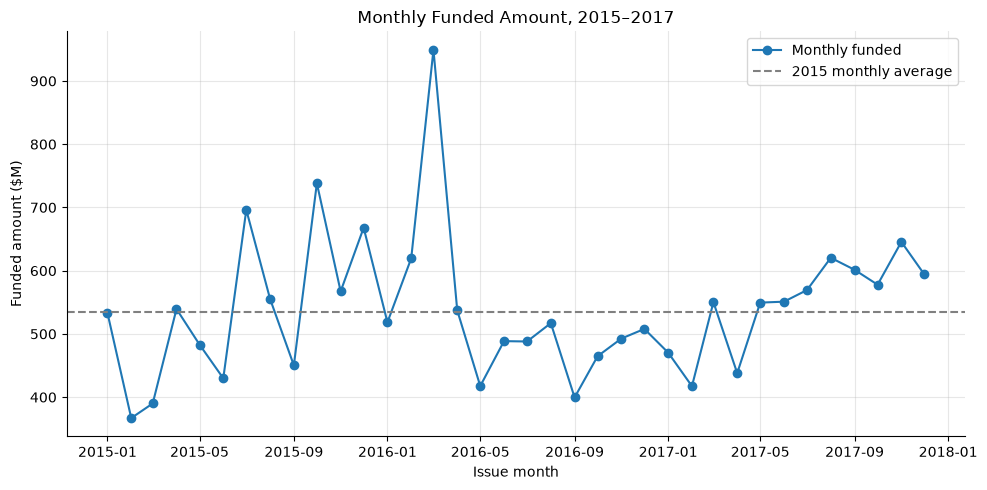

In [3]:
fig, ax = plt.subplots()
ax.plot(monthly["issue_month"], monthly["funded_mm"], marker="o", label="Monthly funded")
ax.axhline(baseline_2015, linestyle="--", color="gray", label="2015 monthly average")
ax.set_title("Monthly Funded Amount, 2015–2017")
ax.set_xlabel("Issue month")
ax.set_ylabel("Funded amount ($M)")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "monthly_funded_2015_2017.png", dpi=150)
plt.show()

## 2. Month-over-month change with `LAG`
Ratios are computed on unrounded amounts; rounding happens only for display.

In [4]:
mom = con.sql("""
WITH monthly AS (
    SELECT DATE_TRUNC('month', issue_date) AS issue_month,
           SUM(funded_amnt) / 1000000      AS funded_mm
    FROM loans_clean
    WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
    GROUP BY issue_month
)
SELECT issue_month,
       ROUND(funded_mm, 1)                                                     AS funded_mm,
       ROUND(LAG(funded_mm) OVER (ORDER BY issue_month), 1)                    AS prev_month_mm,
       ROUND(funded_mm / LAG(funded_mm) OVER (ORDER BY issue_month) - 1, 4)    AS mom_change
FROM monthly
ORDER BY mom_change
LIMIT 5
""").df()
mom

,issue_month,funded_mm,prev_month_mm,mom_change
0,2016-04-01,537.3,949.4,-0.4341
1,2015-02-01,366.9,533.1,-0.3118
2,2015-11-01,567.2,738.2,-0.2316
3,2016-09-01,399.5,517.1,-0.2273
4,2016-01-01,518.4,667.9,-0.2238


The largest MoM drops all follow an unusually **high** prior month: Apr-2016 follows the March spike, and Nov-2015 follows October. In 2015, peaks cluster in **quarter-start months (Apr, Jul, Oct)**, a seasonal pattern whose cause (marketing cadence, investor funding cycles, business days) still needs to be confirmed. MoM is therefore noisy; the real question is the level versus a stable baseline.

## 3. Real decline vs. 2015 baseline

In [5]:
monthly["vs_2015_avg"] = monthly["funded_mm"] / baseline_2015 - 1
period = monthly["issue_month"].between("2016-05-01", "2017-04-01")
trough = monthly.loc[period]
print(f"May-2016 to Apr-2017: ${trough['funded_mm'].min():,.0f}M – ${trough['funded_mm'].max():,.0f}M per month")
print(f"Average gap vs. 2015 run-rate: {trough['vs_2015_avg'].mean():.1%}")
monthly.assign(funded_mm=monthly["funded_mm"].round(1), vs_2015_avg=monthly["vs_2015_avg"].round(3))

May-2016 to Apr-2017: $400M – $550M per month
Average gap vs. 2015 run-rate: -11.9%


,issue_month,n_loans,funded_mm,vs_2015_avg
0,2015-01-01,35107,533.1,-0.003
1,2015-02-01,23770,366.9,-0.314
2,2015-03-01,25400,390.0,-0.271
3,2015-04-01,35427,539.4,0.009
4,2015-05-01,31913,483.2,-0.097
5,2015-06-01,28485,429.8,-0.196
6,2015-07-01,45962,696.2,0.302
7,2015-08-01,35886,555.3,0.038
8,2015-09-01,28641,450.2,-0.158
9,2015-10-01,48631,738.2,0.380


## 4. Next steps
1. **Decompose**: funded volume = applications × approval rate × average loan size. Which component moved in Q2-2016?
2. **Slice** by grade, state and channel to see whether the drop is broad-based or concentrated.
3. **External drivers**: investor funding supply (Lending Club is a marketplace lender), competitor activity, news and regulation.
4. Use **year-over-year** comparisons (`LAG(x, 12)`) to separate seasonality from trend.